<a href="https://colab.research.google.com/github/OJB-Quantum/Qiskit-Metal-to-Litho/blob/main/Python%20Code_Qiskit%20Metal_Designs/3_Xmons_and_Resonators_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authored by Onri Jay Benally (2026)

Open Access (CC-BY-4.0)

# Three-Xmon Readout Chip

Quantum Metal builds three Xmon capacitors and three readout resonators below a shared coplanar waveguide (CPW) feedline on a 10 × 10 mm chip. Four native `RouteStraight` segments connect the launchpads through the primary pins of three `CoupledLineTee` components, while each `RouteMeander` joins a north-facing qubit claw to a tee's `second_end` pin. Native `jj_manhattan` components supply the three Josephson junction mask patterns on a separate layer.


## Layout parameters

| Parameter | Value or Quantum Metal option |
| --- | --- |
| Chip X size (`CHIP_SIZE_X`) | 10 mm |
| Chip Y size (`CHIP_SIZE_Y`) | 10 mm |
| Qubit positions (`QUBIT_X_MM`) | $x=-3.0,0.2,3.4$ mm; $y=0$ |
| Xmon cross width and gap | 20 µm and 16 µm |
| Cross-length scales (`CROSS_LENGTH_SCALE`) | 0.94, 1.00, 1.06 applied to 200 µm |
| Qubit orientation | 0° |
| North readout claw | Pin `a`, length 30 µm, width 10 µm, gap 6 µm, ground spacing 5 µm |
| Claw CPW extension | Length 40 µm, width 10 µm |
| Feedline center (`FEEDLINE_Y`) | $y=2$ mm |
| Feedline and resonator CPW | Width 10 µm, gap 6 µm |
| Total resonator lengths (`RESONATOR_LENGTH`) | 6 mm each, including the meander and secondary tee arm |
| Resonator fillet | 99 µm |
| Native meander spacing and asymmetry | 322 µm and 0 µm |
| Resonator leads | 200 µm at both endpoints |
| Feedline couplers | Three native `CoupledLineTee` components at the qubit X coordinates, $y=2$ mm, orientation 0° |
| Tee primary connections | `prime_start` and `prime_end`, connected in a continuous feedline chain |
| Tee-to-resonator connections | `second_end` to the native resonator route |
| Coupler geometry | Coupling length 200 µm, secondary exit length 110 µm, circular fillet radius 25 µm |
| Coupling ground strip | `coupling_space=4um`, between the two CPW gap boundaries |
| Parallel metal-edge separation | $6+4+6=16$ µm |
| Coupler termination | `open_termination=True`, an open-ended secondary arm |
| Coupler arm length | 299.269908 µm, including its circular-bend correction |
| Meander length | 5700.730092 µm |
| Feedline route count | 4, between launchpads and successive tee primary pins |
| Launchpad origins (`LAUNCHPAD_X`) | $x=±4.25$ mm, $y=2$ mm; orientations 0° and 180° |
| Launchpad tie positions | $x=±4.20$ mm, $y=2$ mm |
| Launchpad geometry | Width 300 µm, body length 240 µm, taper 300 µm, lead 50 µm, gap 144 µm |
| Launchpad clearance X bounds | −4.934 mm to +4.934 mm, inside the chip |
| Manhattan junction pattern | Native pad dimensions 25 × 10 µm, finger dimensions 1 × 20 µm, extension 1 µm |
| Junction origin offsets | −35 µm in X and −18 µm in Y from each south-gap midpoint |
| GDS layer 1 | Positive ground, qubit islands, resonators, feedline, and launchpads |
| GDS layer 15 | Native Manhattan junction mask patterns |
| Ground-plane cheesing | Native 25 × 25 µm square holes, 100 µm center-to-center pitch |
| Component keep-out | Native `no_cheese.buffer=50um`, protecting the circular bends and components |
| Chip-edge keep-out | Hole boundaries stay at least 100 µm inside every chip edge |
| GDS precision | 1 nm |

| Qubit | X position (mm) | Cross length (µm) | Junction origin (µm) | Resonator length (mm) |
| --- | --- | --- | --- | --- |
| `Q0` | −3.0 | 188 | (−3035, −214) | 6.0 |
| `Q1` | 0.2 | 200 | (165, −226) | 6.0 |
| `Q2` | 3.4 | 212 | (3365, −238) | 6.0 |

The resonator length $\ell$ includes the meander length $\ell_m$ and the secondary tee-arm length $\ell_c$, with circular-bend corrections included in both terms.

$$
\ell=\ell_m+\ell_c=5.700730092\,\mathrm{mm}+0.299269908\,\mathrm{mm}=6.000000000\,\mathrm{mm}.
$$

Each tee couples its parallel secondary conductor to the feedline, and `open_termination=True` supplies an open boundary at the unconnected end of that secondary arm. Layer 15 holds the native Manhattan polygons.

## API documentation

[Quantum Metal installation](https://qiskit-community.github.io/qiskit-metal/installation.html) · [Transmon cross options](https://qiskit-community.github.io/qiskit-metal/apidocs/qiskit_metal.qlibrary.TransmonCross.html) · [Manhattan junction options](https://qiskit-community.github.io/qiskit-metal/apidocs/qiskit_metal.qlibrary.jj_manhattan.html) · [Coupled-line tee options](https://qiskit-community.github.io/qiskit-metal/apidocs/qiskit_metal.qlibrary.CoupledLineTee.html) · [Native meander routing](https://qiskit-community.github.io/qiskit-metal/tut/2-From-components-to-chip/2.12-Simple-Meander.html) · [Built-in cheesing and keep-out options](https://qiskit-community.github.io/qiskit-metal/tut/3-Renderers/3.2-Export-your-design-to-GDS.html)

In [14]:
# In Colab / Binder, uncomment to install Quantum Metal (lite, no Qt).
# Locally you should already have it via `pip install quantum-metal` or
# `pip install 'quantum-metal[gui]'` for the desktop GUI.
!uv pip install -q quantum-metal

In [15]:
"""This script builds three Xmons and readout resonators in Quantum Metal."""

# --- Control Knobs ---
CHIP_SIZE_X = "10mm"
CHIP_SIZE_Y = "6mm"
QUBIT_X_MM = (-3.0, 0.2, 3.4)
CROSS_LENGTH_SCALE = (0.94, 1.00, 1.06)
RESONATOR_LENGTH = "6mm"
FEEDLINE_Y = "2mm"
LAUNCHPAD_X = "4.25mm"
METAL_LAYER = 1
JUNCTION_LAYER = 15
OUTPUT_FILENAME = "3_Xmon_Qubits.gds"

# --- Imports and Design ---
import logging
import os
from importlib.metadata import version
from pathlib import Path

os.environ.setdefault("QISKIT_METAL_HEADLESS", "True")

import gdstk
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import qiskit_metal as qm
from IPython.display import FileLink, display
from matplotlib.collections import PolyCollection
from qiskit_metal import Dict, designs
from qiskit_metal.qlibrary.couplers.coupled_line_tee import CoupledLineTee
from qiskit_metal.qlibrary.qubits.JJ_Manhattan import jj_manhattan
from qiskit_metal.qlibrary.qubits.transmon_cross import TransmonCross
from qiskit_metal.qlibrary.terminations.launchpad_wb import LaunchpadWirebond
from qiskit_metal.qlibrary.tlines.meandered import RouteMeander
from qiskit_metal.qlibrary.tlines.straight_path import RouteStraight
from qiskit_metal.renderers.renderer_gds.gds_renderer import QGDSRenderer
from qiskit_metal.validation import validate

plt.rcParams["figure.dpi"] = 250

assert len(QUBIT_X_MM) == len(CROSS_LENGTH_SCALE) == 3
assert METAL_LAYER != JUNCTION_LAYER
design = designs.DesignPlanar(overwrite_enabled=True, enable_renderers=False)
design.chips.main.size.size_x = CHIP_SIZE_X
design.chips.main.size.size_y = CHIP_SIZE_Y
design.variables.cpw_width = "10um"
design.variables.cpw_gap = "6um"
gds_renderer = QGDSRenderer(design)
design.renderers.gds = gds_renderer
qubits, junctions, resonators, couplers, launchpads, feedlines = [], [], [], [], [], []
length_records = []
print(f"Quantum Metal {version('quantum-metal')}")

Quantum Metal 0.9.0


In [16]:
# --- Wirebond Launchpads ---
for name, sign, angle in (("LP_Left", -1, 0), ("LP_Right", 1, 180)):
    launchpads.append(LaunchpadWirebond(
        design, name,
        options=Dict(
            pos_x=f"{sign * design.parse_value(LAUNCHPAD_X)}mm",
            pos_y=FEEDLINE_Y, orientation=str(angle), layer=str(METAL_LAYER),
            trace_width="10um", trace_gap="6um", lead_length="50um",
            pad_width="300um", pad_height="240um", pad_gap="144um",
            taper_height="300um",
        ),
    ))

# --- Xmons, Junction Patterns, and Readout Resonators ---
for index, (x_mm, scale) in enumerate(zip(QUBIT_X_MM, CROSS_LENGTH_SCALE)):
    cross_length_um = 200 * scale
    qubit = TransmonCross(
        design, f"Q{index}",
        options=Dict(
            pos_x=f"{x_mm}mm", pos_y="0mm", orientation="0",
            layer=str(METAL_LAYER), cross_width="20um", cross_gap="16um",
            cross_length=f"{cross_length_um}um",
            connection_pads=Dict(a=Dict(
                connector_location="90", connector_type="0",
                claw_length="30um", claw_width="10um", claw_gap="6um",
                claw_cpw_length="40um", claw_cpw_width="10um",
                ground_spacing="5um",
            )),
        ),
    )
    junction = jj_manhattan(
        design, f"JJ{index}",
        options=Dict(
            pos_x=f"{x_mm - 0.035}mm",
            pos_y=f"{-cross_length_um - 8 - 18}um",
            layer=str(JUNCTION_LAYER),
            JJ_pad_lower_width="25um", JJ_pad_lower_height="10um",
            finger_lower_width="1um", finger_lower_height="20um",
            extension="1um",
        ),
    )
    coupler = CoupledLineTee(
        design, f"CLT{index}",
        options=Dict(
            pos_x=f"{x_mm}mm", pos_y=FEEDLINE_Y, orientation="0",
            layer=str(METAL_LAYER), prime_width="10um", prime_gap="6um",
            second_width="10um", second_gap="6um",
            coupling_length="200um", coupling_space="4um",
            down_length="110um", fillet="25um", open_termination=True,
        ),
    )
    secondary = coupler.qgeometry_table("path")
    secondary = secondary[secondary.name == "second_cpw"].iloc[0]
    coupler_length_mm = (
        secondary.geometry.length - (2 - np.pi / 2) * float(secondary.fillet)
    )
    target_mm = float(design.parse_value(RESONATOR_LENGTH))
    resonator = RouteMeander(
        design, f"Res{index}",
        options=Dict(
            layer=str(METAL_LAYER), trace_width="10um", trace_gap="6um",
            pin_inputs=Dict(
                start_pin=Dict(component=qubit.name, pin="a"),
                end_pin=Dict(component=coupler.name, pin="second_end"),
            ),
            total_length=f"{target_mm - coupler_length_mm:.12f}mm", fillet="99um",
            lead=Dict(start_straight="200um", end_straight="200um"),
            meander=Dict(spacing="322um", asymmetry="0um"),
            prevent_short_edges="true",
        ),
    )
    qubits.append(qubit)
    junctions.append(junction)
    couplers.append(coupler)
    resonators.append(resonator)
    length_records.append({
        "qubit": qubit.name, "x_mm": x_mm,
        "cross_length_um": cross_length_um,
        "target_mm": target_mm,
        "meander_mm": resonator.length,
        "coupler_mm": coupler_length_mm,
        "total_mm": resonator.length + coupler_length_mm,
        "error_um": 1000 * (resonator.length + coupler_length_mm - target_mm),
    })

# --- Feedline through Native Tee Primary Pins ---
feed_starts = [Dict(component="LP_Left", pin="tie")] + [
    Dict(component=coupler.name, pin="prime_end") for coupler in couplers
]
feed_ends = [
    Dict(component=coupler.name, pin="prime_start") for coupler in couplers
] + [Dict(component="LP_Right", pin="tie")]
for index, (start_pin, end_pin) in enumerate(zip(feed_starts, feed_ends)):
    feedlines.append(RouteStraight(
        design, f"Feedline{index}",
        options=Dict(
            layer=str(METAL_LAYER), trace_width="10um", trace_gap="6um",
            pin_inputs=Dict(start_pin=start_pin, end_pin=end_pin),
        ),
    ))

# --- Geometry and Length Checks ---
length_table = pd.DataFrame(length_records)
assert length_table.error_um.abs().max() < 0.01
chip_bounds, chip_status = design.get_x_y_for_chip("main")
assert chip_status == 0
for component in design.components.values():
    assert component.status == "good", component.name
    xmin, ymin, xmax, ymax = component.qgeometry_bounds()
    assert xmin >= chip_bounds[0] and ymin >= chip_bounds[1], component.name
    assert xmax <= chip_bounds[2] and ymax <= chip_bounds[3], component.name
for table_name in ("poly", "path"):
    table = design.qgeometry.tables[table_name]
    assert table.geometry.is_valid.all(), table_name
    assert not table.geometry.is_empty.any(), table_name
drc = validate(design)
drc.raise_if_errors()
print(drc.report())
display(length_table.round(6))
print(f"{len(qubits)} Xmons; {len(resonators)} resonators; "
      f"{len(couplers)} coupled-line tees; {len(junctions)} junction patterns")

  self.tables[kind] = pd.concat(



Design rules passed (11 rules ran, no findings).


,qubit,x_mm,cross_length_um,target_mm,meander_mm,coupler_mm,total_mm,error_um
0,Q0,-3.0,188.0,6.0,5.70073,0.29927,6.0,-0.0
1,Q1,0.2,200.0,6.0,5.70073,0.29927,6.0,-0.0
2,Q2,3.4,212.0,6.0,5.70073,0.29927,6.0,-0.0


3 Xmons; 3 resonators; 3 coupled-line tees; 3 junction patterns


  geopandas.GeoDataFrame(pd.concat(copy_subtract, ignore_index=False))

  geopandas.GeoDataFrame(pd.concat(copy_no_subtract, ignore_index=False))



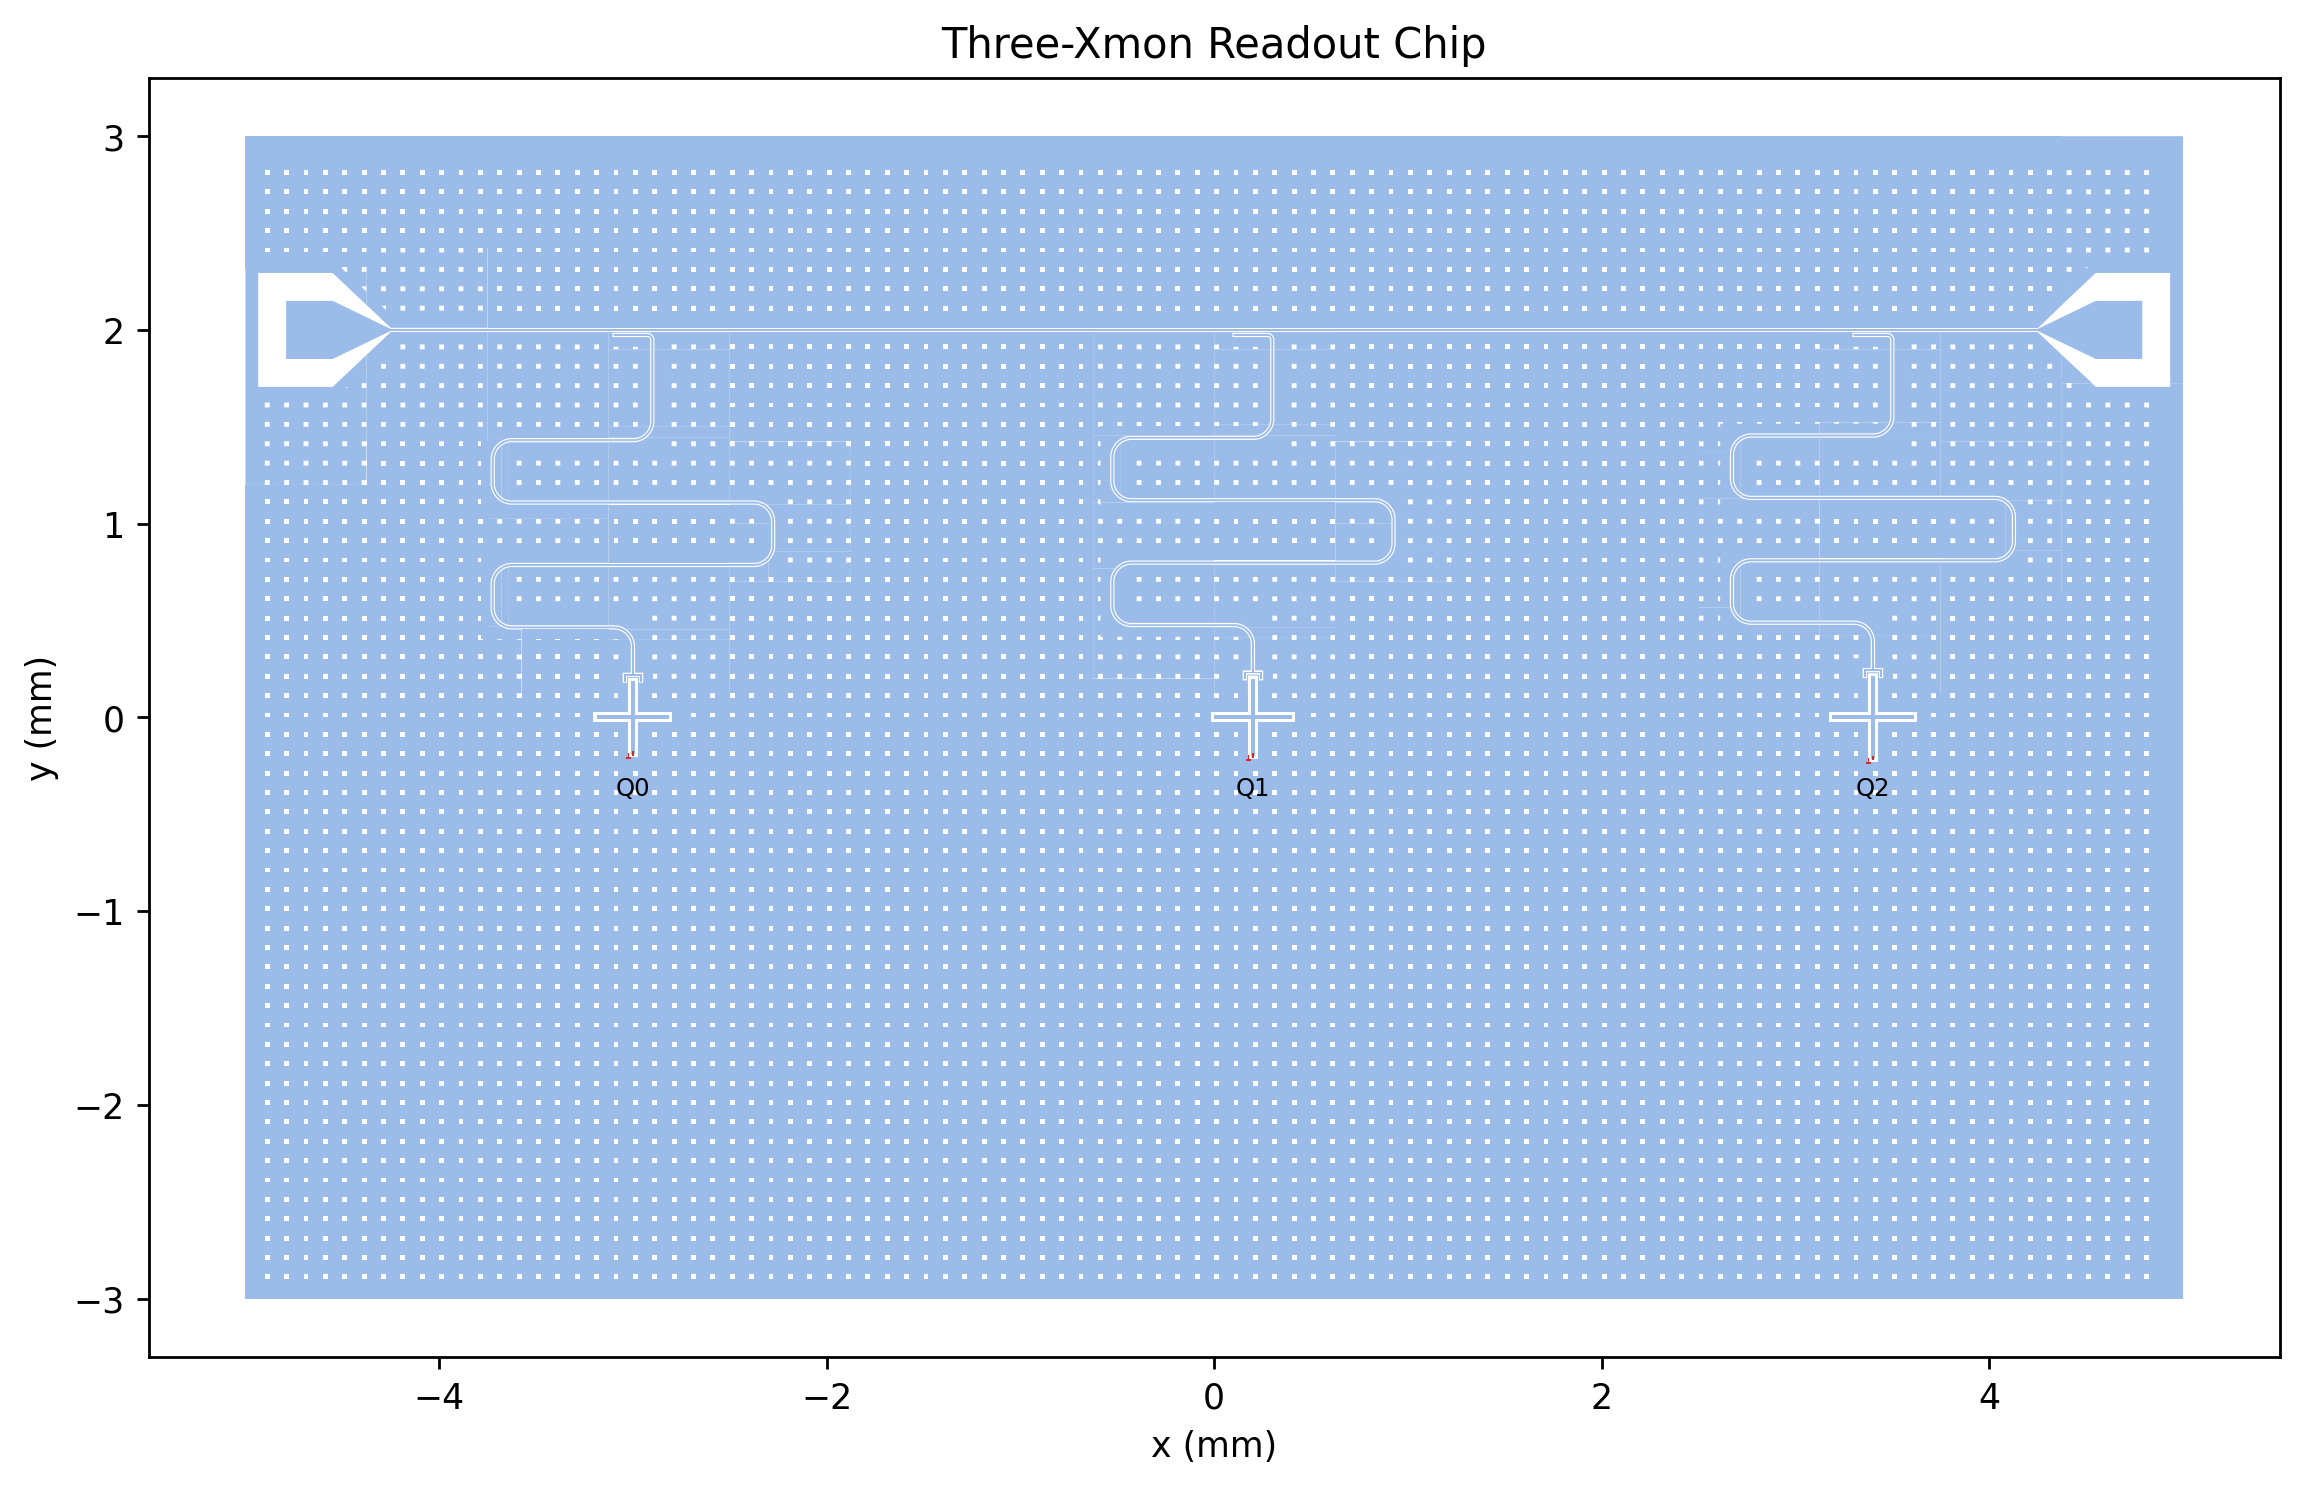

GDSII: 3_Xmon_Qubits.gds (406,070 bytes)
Layers: 1 = ground/readout metal; 15 = Manhattan junction patterns


/content/3_Xmon_Qubits.gds

In [17]:
# --- Native Cheesing and GDS Export ---
out = Path.cwd() / OUTPUT_FILENAME
gds_renderer.options.precision = "1e-9"
gds_renderer.options.tolerance = "1e-6"
gds_renderer.options.fabricate = "True"
gds_renderer.options.short_segments_to_not_fillet = "False"
gds_renderer.options.path_filename = ""

gds_renderer.options.cheese = QGDSRenderer.default_options.cheese.copy()
# Hole-center inset = 100 um edge clearance + half the default 25 um hole width.
gds_renderer.options.cheese.edge_nocheese = "112.5um"
gds_renderer.options.cheese.view_in_file = Dict(main={
    METAL_LAYER: True, JUNCTION_LAYER: False,
})
gds_renderer.options.no_cheese.buffer = "50um"
gds_renderer.options.no_cheese.view_in_file = Dict(main={
    METAL_LAYER: False, JUNCTION_LAYER: False,
})

# Manhattan junction polygons already occupy their own mask layer.
junction_table = design.qgeometry.tables["junction"].copy(deep=True)
design.qgeometry.tables["junction"] = junction_table.iloc[:0].copy()
previous_log_level = qm.logger.level
qm.logger.setLevel(logging.ERROR)
try:
    export_status = gds_renderer.export_to_gds(str(out))
finally:
    qm.logger.setLevel(previous_log_level)
    design.qgeometry.tables["junction"] = junction_table
assert export_status and out.is_file() and out.stat().st_size > 0

# Keep references only to cells present in the exported library.
cell_names = {cell.name for cell in gds_renderer.lib.cells}
for cell in gds_renderer.lib.cells:
    for reference in list(cell.references):
        if reference.cell_name not in cell_names:
            cell.remove(reference)
gds_renderer.lib.write_gds(str(out))

# --- Export Checks ---
verified_gds = gdstk.read_gds(str(out))
top_cells = verified_gds.top_level()
assert len(top_cells) == 1
exported_polygons = top_cells[0].get_polygons()
assert {polygon.layer for polygon in exported_polygons} == {
    METAL_LAYER, JUNCTION_LAYER,
}
assert np.isclose(verified_gds.precision, 1e-9)
assert sum(polygon.layer == JUNCTION_LAYER
           for polygon in exported_polygons) == len(junctions)

# --- In-Memory GDS Preview ---
fig, ax = plt.subplots(figsize=(11, 11), dpi=250)
for layer, color in ((METAL_LAYER, "#9bbce8"), (JUNCTION_LAYER, "#d62728")):
    ax.add_collection(PolyCollection(
        [polygon.points for polygon in exported_polygons if polygon.layer == layer],
        facecolor=color, edgecolor="none", rasterized=True,
    ))
ax.autoscale_view()
ax.set_aspect("equal")
ax.set(xlabel="x (mm)", ylabel="y (mm)", title="Three-Xmon Readout Chip")
for qubit in qubits:
    ax.text(qubit.p.pos_x, qubit.p.pos_y - 0.4, qubit.name,
            ha="center", fontsize=7, fontfamily="DejaVu Sans", weight="normal")
plt.show()

print(f"GDSII: {out.name} ({out.stat().st_size:,} bytes)")
print(f"Layers: {METAL_LAYER} = ground/readout metal; "
      f"{JUNCTION_LAYER} = Manhattan junction patterns")
display(FileLink(str(out)))